# Notebook 1 — The RAG Pipeline

A large language model learned from public text, up to a certain date. It has never seen
your company's handbook, your contracts, or your notes. If you ask about them, it guesses.

**RAG (Retrieval-Augmented Generation)** fixes this: first find the parts of your documents
that match the question, then give them to the model together with the question, and let it
answer from them.

**What you will learn**

1. Why a model needs RAG.
2. The two phases of RAG: indexing, and retrieval + generation.
3. What embeddings are and how similarity search works.
4. Vector stores, retrievers, and choosing top-k.
5. A complete RAG chain that also shows its sources.
6. Where RAG goes wrong, and what helps.

**Before you start**

```bash
ollama pull gpt-oss:20b        # chat model
ollama pull nomic-embed-text   # embedding model (~270 MB)
uv sync
```

Then choose the `.venv` Python kernel for this notebook. ⏱️ About 45 minutes.

## 1. Setup

`get_embeddings()` is new in the `roadmap` package. It returns a LangChain embedding model
that runs in Ollama (`nomic-embed-text` by default).

In [1]:
from operator import itemgetter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import Language, RecursiveCharacterTextSplitter

from roadmap import get_chat_model, get_embeddings

llm = get_chat_model()
embeddings = get_embeddings()
print("Chat model:     ", llm.model)
print("Embedding model:", embeddings.model)

DATA = Path("data")
ASSETS = Path("assets")
ASSETS.mkdir(exist_ok=True)

Chat model:      gpt-oss:20b
Embedding model: nomic-embed-text


## 2. The problem: the model does not know your documents

![Why RAG? The model does not know your documents](assets/rag_why.svg)

Our example is **Brightleaf**, a made-up software company. Its employee handbook is in
[`data/handbook.md`](data/handbook.md). The model has never seen it. Let's ask it anyway:

In [2]:
QUESTIONS = [
    "How many vacation days do Brightleaf employees get?",
    "What is the dress code at Brightleaf?",
    "Can I eat in Brightleaf company vehicles?",
]

for question in QUESTIONS:
    answer = llm.invoke(f"{question} Answer in one or two sentences.").content
    print(f"Q: {question}\nA: {answer}\n")

Q: How many vacation days do Brightleaf employees get?
A: Brightleaf employees receive **15 paid vacation days per year**.



Q: What is the dress code at Brightleaf?
A: Brightleaf’s dress code is business casual—smart, neat attire that’s comfortable yet professional. Employees can wear polo shirts, blouses, chinos, or dresses, but should avoid overly casual items like ripped jeans, flip‑flops, or sleeveless tops.



Q: Can I eat in Brightleaf company vehicles?
A: No – company vehicles are considered work equipment, and eating inside them is prohibited unless you’re in a designated break area or the vehicle is parked and you’re not operating it.



The answers sound sure, but they are **invented**. The handbook gives 28 vacation days and
says nothing about a dress code. Sometimes a guess is close to the truth, but you cannot tell
a good guess from a bad one. Making things up like this is called **hallucination**.

## 3. The RAG pipeline

![The RAG pipeline](assets/rag_pipeline.svg)

RAG has two phases:

| Phase | When | Steps |
|---|---|---|
| **Indexing** | once, before any question | load the documents → split them into chunks → turn each chunk into a vector → store the vectors |
| **Retrieval and generation** | for every question | turn the question into a vector → find the closest chunks → put them into the prompt → let the LLM answer |

The next sections build each step, one at a time.

## 4. Load the document

> **Document:** LangChain's container for text. It has `page_content` (the text) and
> `metadata` (extra facts, such as which file it came from).

Loading a plain text file takes two lines. Notebook 2 shows how to load PDFs and web pages.

In [3]:
text = (DATA / "handbook.md").read_text()
handbook = Document(page_content=text, metadata={"source": "handbook.md"})

print(f"{len(text)} characters\n")
print(text[:400])

5078 characters

# Brightleaf Employee Handbook

Brightleaf is a made-up software company. This handbook is sample data for the roadmap
notebooks. Every name, number, and rule in it is invented.

Version 3.2, valid from January 2026.

## 1. Working hours

Our core hours are 10:00 to 15:00, Monday to Friday. Inside core hours, everyone should be
reachable for meetings. Outside core hours, you can plan your day free


## 5. Split it into chunks

> **Chunk:** a small piece of a document. RAG searches over chunks, not whole documents.

Why split?

- **Better search.** A small chunk is about one thing, so it matches a question more clearly.
- **Shorter prompts.** Only the few chunks that matter go into the prompt, not the whole file.

We split at Markdown headings first, so each chunk is one handbook section (or part of one).
A chunk may have at most 500 characters, and neighboring chunks share up to 50 characters
(the **overlap**), so a sentence cut in two is not lost. Notebook 2 explains splitting in
detail.

In [4]:
splitter = RecursiveCharacterTextSplitter.from_language(
    Language.MARKDOWN, chunk_size=500, chunk_overlap=50
)
chunks = splitter.split_documents([handbook])


def title(doc: Document) -> str:
    """A short label for a chunk: its first line, without the Markdown '#' signs."""
    first_line = doc.page_content.splitlines()[0].lstrip("# ")
    return first_line if len(first_line) <= 32 else first_line[:30] + "..."


print(f"{len(chunks)} chunks\n")
for number, chunk in enumerate(chunks):
    print(f"{number:>2}  {len(chunk.page_content):>3} characters  {title(chunk)}")

15 chunks

 0  216 characters  Brightleaf Employee Handbook
 1  407 characters  1. Working hours
 2  347 characters  2. Remote work
 3  177 characters  Brightleaf pays a home office ...
 4  434 characters  3. Vacation
 5  260 characters  4. Sick leave
 6  312 characters  5. Parental leave
 7  471 characters  6. Expenses and travel
 8  415 characters  7. Company vehicles
 9  422 characters  8. Equipment and IT security
10  350 characters  9. Mobile phone policy
11  364 characters  10. Learning and growth
12  337 characters  11. Code of conduct
13  334 characters  12. Health and safety
14  203 characters  13. Contact


Each chunk keeps the metadata of the document it came from. Section 2 ("Remote work") is
longer than 500 characters, so it was split into two chunks: chunk 3 is its second half and
starts in the middle of the section, without a heading.

## 6. Embeddings: meaning as numbers

![Embeddings: meaning as numbers](assets/embeddings.svg)

How do we find the chunks that "match" a question, even when they use different words?
With embeddings.

> **Embedding:** a list of numbers (a **vector**) that represents the meaning of a text. An
> **embedding model** creates it. Texts with similar meaning get similar vectors.
>
> **Cosine similarity:** a score for how similar two vectors are. 1 means the same
> direction (same meaning); lower means less related.

In [5]:
sentences = [
    "How many days off do I get?",
    "Vacation days per year",
    "I lost my laptop.",
    "Report stolen devices to the help desk",
    "The cat sat on the mat.",
]
vectors = np.array(embeddings.embed_documents(sentences))

print("Shape:", vectors.shape, "-> one vector of", vectors.shape[1], "numbers per sentence")
print("First 5 numbers of the first vector:", np.round(vectors[0][:5], 3))

Shape: (5, 768) -> one vector of 768 numbers per sentence
First 5 numbers of the first vector: [-0.033  0.041 -0.174 -0.011 -0.025]


The numbers on their own mean nothing to us. What matters is how close two vectors are.
Let's compare every sentence with every other one:

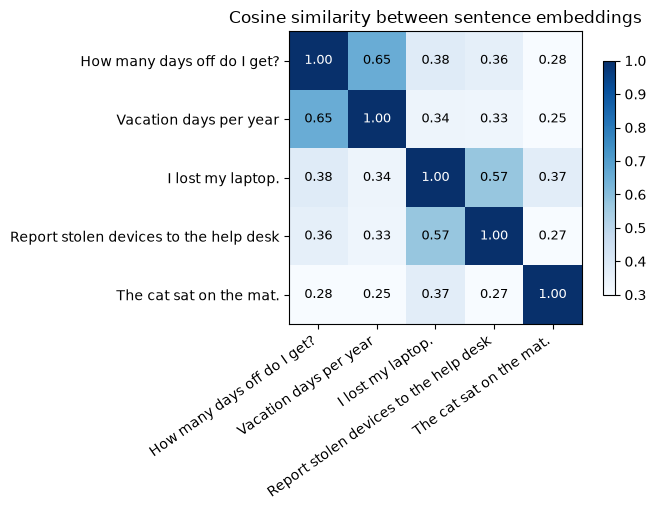

In [6]:
unit = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
similarity = unit @ unit.T  # cosine similarity for every pair

fig, ax = plt.subplots(figsize=(7, 5.2))
image = ax.imshow(similarity, cmap="Blues", vmin=0.3, vmax=1)
ax.set_xticks(range(len(sentences)), sentences, rotation=35, ha="right")
ax.set_yticks(range(len(sentences)), sentences)
for row in range(len(sentences)):
    for col in range(len(sentences)):
        value = similarity[row, col]
        color = "white" if value > 0.75 else "black"
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", color=color, fontsize=9)
ax.set_title("Cosine similarity between sentence embeddings")
fig.colorbar(image, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(ASSETS / "similarity_heatmap.png", dpi=120)
plt.show()

**What to notice**

- "How many days off do I get?" and "Vacation days per year" score high, although they share
  almost no words. The model understands that "days off" and "vacation" mean the same.
- The two sentences about lost devices also match each other well.
- The cat sentence is far from everything else.
- Even unrelated texts score above 0. Only the **ranking** matters: higher means closer.

Stage 3 looks at similarity measures in detail.

## 7. Store the chunks in a vector store

> **Vector store:** a database that keeps each chunk together with its vector, and can
> quickly find the vectors closest to a question's vector.

We use `InMemoryVectorStore`. It keeps everything in memory, which is perfect for learning.
Stage 3 covers real vector databases such as ChromaDB and FAISS.

In [7]:
vector_store = InMemoryVectorStore.from_documents(chunks, embeddings)
print(f"Stored {len(vector_store.store)} chunks with their vectors.")

Stored 15 chunks with their vectors.


`from_documents()` sent every chunk to the embedding model and stored the result. That was
the whole **indexing** phase. It runs once; after that we can ask as many questions as we
like.

## 8. Retrieve the right chunks

For a question, the vector store embeds the question and returns the closest chunks.

> **Top-k (retrieval):** how many chunks the search returns. This is a different "top-k"
> from Stage 1, where top-k limited the next-token choice.

Here are the similarity scores of **all** chunks for one question. With `k=3` we keep the
three highest:

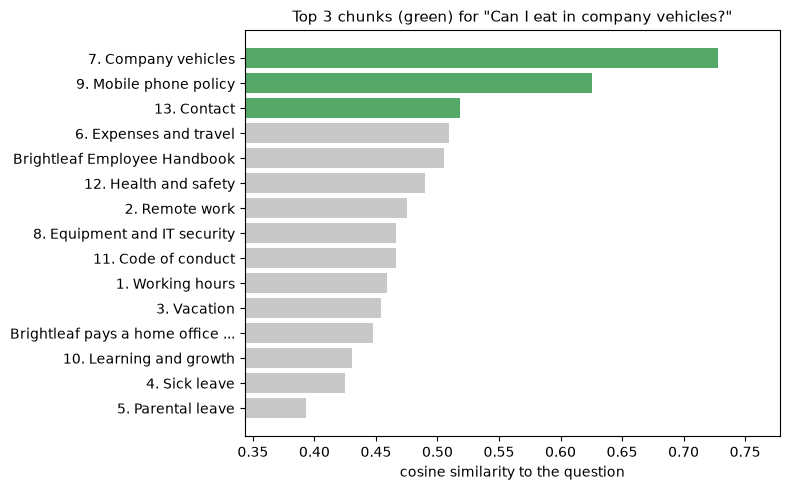

In [8]:
question = "Can I eat in company vehicles?"
k = 3

ranked = vector_store.similarity_search_with_score(question, k=len(chunks))
labels = [title(doc) for doc, _ in ranked][::-1]
scores = [score for _, score in ranked][::-1]
colors = ["#55A868" if rank >= len(ranked) - k else "#C8C8C8" for rank in range(len(ranked))]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(labels, scores, color=colors)
ax.set_xlim(min(scores) - 0.05, max(scores) + 0.05)
ax.set_xlabel("cosine similarity to the question")
ax.set_title(f'Top {k} chunks (green) for "{question}"', fontsize=11)
fig.tight_layout()
fig.savefig(ASSETS / "retrieval_scores.png", dpi=120)
plt.show()

"Company vehicles" wins clearly. To use the search inside a chain, turn the vector store
into a **retriever**:

> **Retriever:** a runnable that takes a question and returns a list of documents.

In [9]:
retriever = vector_store.as_retriever(search_kwargs={"k": 3})

for doc in retriever.invoke("I lost my laptop. Who do I tell?"):
    print("-", title(doc))

- 8. Equipment and IT security
- 13. Contact
- Brightleaf Employee Handbook


## 9. Generate the answer

Now the "G" in RAG. The prompt gives the model the retrieved chunks as **context** and tells
it to answer only from them. This is the **grounding** idea from Stage 1, Notebook 1.

In [10]:
rag_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You answer questions about the Brightleaf employee handbook. Use only the "
            "context below. If the answer is not in the context, say: I don't know, the "
            "handbook does not say.\n\nContext:\n{context}",
        ),
        ("user", "{question}"),
    ]
)


def format_docs(docs: list[Document]) -> str:
    return "\n\n---\n\n".join(doc.page_content for doc in docs)


rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | rag_prompt
    | llm
    | StrOutputParser()
)

The dictionary at the start of the chain runs two things side by side (a parallel chain
from Stage 1, Notebook 2): the question goes to the retriever, whose chunks become
`context`, and it is also passed on unchanged as `question`.

Let's ask the same three questions as in section 2:

In [11]:
for question in QUESTIONS:
    print(f"Q: {question}\nA: {rag_chain.invoke(question)}\n")

Q: How many vacation days do Brightleaf employees get?
A: Full‑time employees at Brightleaf receive **28 vacation days per calendar year**. Part‑time employees receive vacation days in proportion to their working days.



Q: What is the dress code at Brightleaf?
A: I don't know, the handbook does not say.



Q: Can I eat in Brightleaf company vehicles?
A: No. Eating and drinking in Brightleaf company vehicles is not allowed, except for water.



Compare with section 2: the vacation answer is now correct (28 days), the dress code
question gets an honest "I don't know", and the vehicle rule is exact, including the water
exception.

## 10. Show the sources

A good RAG app also shows **where** the answer came from, so people can check it. We keep
the retrieved documents in the result with `RunnablePassthrough.assign`:

In [12]:
answer_chain = rag_prompt | llm | StrOutputParser()

rag_with_sources = (
    RunnablePassthrough.assign(docs=itemgetter("question") | retriever)
    | RunnablePassthrough.assign(context=lambda x: format_docs(x["docs"]))
    | RunnablePassthrough.assign(answer=answer_chain)
)

result = rag_with_sources.invoke({"question": "How much is the learning budget?"})
print(result["answer"])
print("\nSources:")
for doc in result["docs"]:
    print(f"- {doc.metadata['source']}: {title(doc)}")

The learning budget is **1,200 EUR per year**.

Sources:
- handbook.md: 10. Learning and growth
- handbook.md: 6. Expenses and travel
- handbook.md: Brightleaf pays a home office ...


Look at the last two sources: they have nothing to do with the learning budget. A retriever
**always returns k chunks**, even when fewer are relevant. The grounded prompt lets the model
ignore them, but they still make the prompt longer. Stage 4 shows how to drop weak matches.

## 11. When RAG goes wrong

RAG can only be as good as its search. If the right chunk is not retrieved, the model
cannot see it. Here is a real failure with our handbook:

In [13]:
def ask_with_k(question: str, k: int) -> None:
    docs = vector_store.similarity_search(question, k=k)
    answer = answer_chain.invoke({"context": format_docs(docs), "question": question})
    print(f"k={k}: {question}")
    print("  retrieved:", " | ".join(title(doc) for doc in docs))
    print("  answer:   ", answer, "\n")


ask_with_k("How much of the phone bill does Brightleaf pay?", k=3)

k=3: How much of the phone bill does Brightleaf pay?
  retrieved: Brightleaf pays a home office ... | Brightleaf Employee Handbook | 1. Working hours
  answer:    I don't know, the handbook does not say. 



The section "9. Mobile phone policy" was not retrieved. The question says "phone bill" and
"Brightleaf pays", while the handbook says "phone costs are covered". The words "Brightleaf
pays" match a different chunk (the home office allowance) more strongly.

The good news: thanks to grounding, the model says "I don't know" instead of inventing an
amount. Two simple fixes:

In [14]:
ask_with_k("How much of the phone bill does Brightleaf pay?", k=6)
ask_with_k("How much of my work phone costs are covered?", k=3)

k=6: How much of the phone bill does Brightleaf pay?
  retrieved: Brightleaf pays a home office ... | Brightleaf Employee Handbook | 1. Working hours | 10. Learning and growth | 7. Company vehicles | 9. Mobile phone policy
  answer:    Brightleaf covers up to 40 EUR per month of your phone bill. 



k=3: How much of my work phone costs are covered?
  retrieved: 9. Mobile phone policy | Brightleaf pays a home office ... | 13. Contact
  answer:    Up to **40 EUR per month** are covered for your work phone. 



- **A bigger k** finds the right chunk, but it also sends more unrelated text to the model.
- **Wording close to the document** puts the right chunk first.

Better fixes come later: rewriting the question automatically (Notebook 3), and smarter
search such as hybrid search and reranking (Stage 4).

## 12. Summary

| Step | What it does | In code |
|---|---|---|
| Load | Turn a file into `Document` objects | `Document(page_content=..., metadata=...)` |
| Split | Cut documents into chunks | `RecursiveCharacterTextSplitter` |
| Embed | Turn text into vectors | `get_embeddings()` → `OllamaEmbeddings` |
| Store | Keep chunks and vectors searchable | `InMemoryVectorStore.from_documents(...)` |
| Retrieve | Find the top-k closest chunks | `vector_store.as_retriever(search_kwargs={"k": 3})` |
| Generate | Answer from the chunks only | grounded prompt → LLM |
| Sources | Show where the answer came from | keep `docs` with `RunnablePassthrough.assign` |

**Remember:** most RAG problems are search problems. When an answer is wrong, first look at
which chunks were retrieved.

➡️ **Next:** Notebook 2 — Loaders and chunking.